# Cutoff (shell) formulation at small $\Delta_0$

The model is fixed by the $T = 0$ gap $\Delta_0$; $V$ and $m_0$ follow from it (`cs.zero`).
Unknowns are only the excitations $n_\alpha$, $h_\beta = 1 - n_\beta$ in the shell $|\xi| < \Lambda$;
the rest of the band enters through 1D vacuum integrals over the DOS (`cs.lvac`, `cs.mvac`):

$$\int g\Big[\tfrac{1}{2E} - \tfrac{1}{2E_0}\Big] = \sum_{\rm shell} w \Big\langle \tfrac{1}{2E}\Big\rangle (n_\alpha + h_\beta),\qquad
m = -\int g\,\tfrac{\xi}{E} + \sum_{\rm shell} w \Big\langle\tfrac{\xi}{E}\Big\rangle (n_\alpha + h_\beta),\qquad
\sum_{\rm shell} w\,(n_\alpha - h_\beta) = 0 .$$

The code works in $t_a = 1$ eV, $a_0 = 1$; every printed or plotted energy is converted to Kelvin with `cm.kel`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

sys.path.insert(0, str(Path.cwd()))
import cut_model as cm
import cut_solve as cs

kel = cm.kel
band = dict(gap=2.0, ta=1.0, tb=-1.0)
set1_list = plt.get_cmap("Set1").colors
W = 3.47412


def style(ax, x=None):
    ax.grid(alpha=0.3)
    ax.tick_params(which="both", direction="in")
    if x is not None:
        ax.set_xlim(np.min(x), np.max(x))

## 1. Scales for a given $\Delta_0$

`cs.zero` solves the $T = 0$ equations for $V$ and $m_0$ at fixed $\Delta_0$; `cs.tc` solves the subtracted
Thouless equation. Both are 1D integrals in $u = \operatorname{asinh}(\xi / a)$, with no k grid and no $e^{+E/T}$.

In [13]:
d0s = [1.0, 0.1, 0.03, 0.015]
cz = {d0: cs.zero(**band, d0=d0, branch="bec") for d0 in d0s}
tcs = {d0: cs.tc(c) for d0, c in cz.items()}
print("  d0 [K]     V [K]      m0        s*      Tc [K]     d0 / Tc")
for d0, c in cz.items():
    p = c.p
    print(f"{kel(d0):9.2f}  {kel(p.v):9.1f}  {c.m0:+.6f}  {cs.xc(p, c.m0) / (p.ta - p.tb):.4f}  "
          f"{kel(tcs[d0]):9.3f}  {d0 / tcs[d0]:.4f}")

  d0 [K]     V [K]      m0        s*      Tc [K]     d0 / Tc
 11604.52    90569.9  -0.953179  2.3598   6364.361  1.8234
  1160.45    96814.6  -0.999615  2.5849   2354.708  0.4928
   348.14    96861.3  -0.999965  2.5866   1719.124  0.2025
   174.07    96864.8  -0.999991  2.5868   1483.456  0.1173


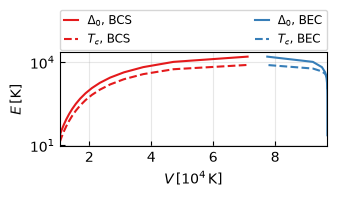

In [14]:
# Delta_0 and Tc on both T = 0 roots: BCS = smallest V, BEC = largest V (one Hartree scan per d0)
dd = np.geomspace(2e-3, 1.37, 16)
rr = [cs.roots(**band, d0=x) for x in dd]
vv = np.array([[r[0].p.v, r[-1].p.v] for r in rr])
tt = np.array([[cs.tc(r[0]), cs.tc(r[-1])] for r in rr])

fig, ax = plt.subplots(figsize=(W, 0.6 * W))
for i, lb in enumerate(["BCS", "BEC"]):
    ax.semilogy(kel(vv[:, i]) / 1e4, kel(dd), color=set1_list[i], label=rf"$\Delta_0$, {lb}")
    ax.semilogy(kel(vv[:, i]) / 1e4, kel(tt[:, i]), "--", color=set1_list[i], label=rf"$T_c$, {lb}")
ax.set_xlabel(r"$V\,[10^4\,\mathrm{K}]$")
ax.set_ylabel(r"$E\,[\mathrm{K}]$")
ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand", borderaxespad=0, ncol=2,
          handlelength=1.2, columnspacing=0.6, fontsize="small")
style(ax, kel(vv) / 1e4)
plt.tight_layout()
plt.show()

## 2. Equilibrium $\Delta(T)$: grid free and on the shell grid

`cs.faces(c, lam, a, n)`: $n$ (odd) cells in $\xi$, sinh spaced, width $a\,du$ at the ring and $|\xi|\,du$ further out.
Here $\Lambda = 40 T_c$ and $a = 0.1 \Delta_0$. The cells are fixed in $\xi$ and move with $m$ in $s$ (`cs.cells`).

d0 = 1160.45 K, Tc = 2354.708 K: max |d_shell - d_quad| = 2.06e-02 K (n = 401)


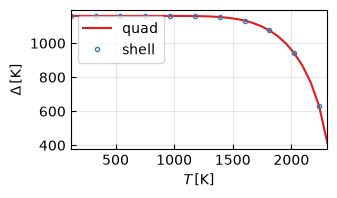

d0 = 174.07 K, Tc = 1483.456 K: max |d_shell - d_quad| = 3.17e-03 K (n = 401)


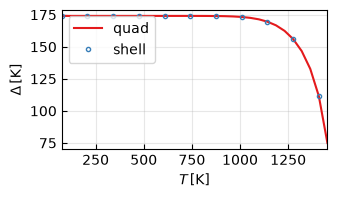

In [15]:
tr = np.linspace(0.05, 0.98, 32)
for i, d0 in enumerate([0.1, 0.015]):
    c, tc = cz[d0], tcs[d0]
    dq, z = [], (d0, c.m0)
    for t in tr * tc:                                  # continuation in T
        z = cs.thermal(c, t, *z)[:2]
        dq.append(z)
    dq = np.array(dq)
    xf = cs.faces(c, 40 * tc, 0.1 * d0, 401)
    ds = np.array([cs.thermal_shell(c, xf, t, *z)[0] for t, z in zip(tr[::3] * tc, dq[::3])])
    print(f"d0 = {kel(d0):.2f} K, Tc = {kel(tc):.3f} K: max |d_shell - d_quad| = "
          f"{np.max(np.abs(kel(ds - dq[::3, 0]))):.2e} K (n = 401)")

    fig, ax = plt.subplots(figsize=(W, 0.6 * W))
    ax.plot(kel(tr * tc), kel(dq[:, 0]), color=set1_list[0], label="quad")
    ax.plot(kel(tr[::3] * tc), kel(ds), "o", ms=3, mfc="none", color=set1_list[1], label="shell")
    ax.set_xlabel(r"$T\,[\mathrm{K}]$")
    ax.set_ylabel(r"$\Delta\,[\mathrm{K}]$")
    ax.legend()
    style(ax, kel(tr * tc))
    plt.tight_layout()
    plt.show()

In [16]:
# shell discretization error at 0.95 Tc against the number of cells (second order)
for d0 in [0.1, 0.015]:
    c, tc = cz[d0], tcs[d0]
    d, m, _ = cs.thermal(c, 0.95 * tc)
    er = [kel(cs.thermal_shell(c, cs.faces(c, 40 * tc, 0.1 * d0, n), 0.95 * tc, d, m)[0] - d)
          for n in (201, 401, 801)]
    print(f"d0 = {kel(d0):.2f} K, d(0.95 Tc) = {kel(d):.4f} K: d_shell - d_quad = "
          + ", ".join(f"{e:+.2e} K" for e in er) + "  (n = 201, 401, 801)")

d0 = 1160.45 K, d(0.95 Tc) = 629.7880 K: d_shell - d_quad = +8.21e-02 K, +2.06e-02 K, +5.17e-03 K  (n = 201, 401, 801)
d0 = 174.07 K, d(0.95 Tc) = 111.4937 K: d_shell - d_quad = +1.26e-02 K, +3.17e-03 K, +7.96e-04 K  (n = 201, 401, 801)


## 3. Moving ring

The ring moves by $\delta\xi = \tfrac{h}{2}(m - m_0)$, i.e. $\delta s^* = -h (m - m_0) / 2(t_a - t_b)$.
The cells move with it, so only the weights change.

In [17]:
for d0 in [0.1, 0.015]:
    c, tc = cz[d0], tcs[d0]
    xf = cs.faces(c, 40 * tc, 0.1 * d0, 401)
    _, m, _ = cs.thermal(c, 0.95 * tc)
    dx = 0.5 * c.p.h * (m - c.m0)
    print(f"d0 = {kel(d0):.2f} K: ring shift at 0.95 Tc {kel(dx):+.3f} K, "
          f"central cell {kel(np.min(np.diff(xf))):.3f} K, shell edge {kel(xf[-1]):.1f} K")

d0 = 1160.45 K: ring shift at 0.95 Tc -9.655 K, central cell 2.135 K, shell edge 92836.1 K
d0 = 174.07 K: ring shift at 0.95 Tc -0.187 K, central cell 0.383 K, shell edge 59338.3 K


## 4. NESS at $\Delta_0 = 0.015$ ($T_c \approx 99$ K)

Photon at $T_1$ (vertical, $\omega_0 = 0$, $\gamma = 0.1\Delta_0$), phonon at $T_2$ (Fokker-Planck).
The phonons conserve the band numbers and are about $10^{16}$ times faster than the photons on the fine cells,
so the $\mu$ rows cannot fix the pair number $N_\alpha + H_\beta$. `cs.resid` therefore adds the row
`cs.jlog` $= 0$ (summed interband photon balance), which every steady state satisfies.

In [18]:
d0 = 0.015
c, tc = cz[d0], tcs[d0]
pc = dict(amp=1.0, dip=2.0, c=200.0, w0=0.0, gam=0.1 * d0)
qc = dict(amp=1.0, ta_prime=-1.0, tb_prime=1.0, line="fp", gam=0.1 * d0)
t1, t2 = 0.6 * tc, 0.2 * tc
xf = cs.faces(c, 40 * tc, 0.1 * d0, 401)
print(f"T1 = {kel(t1):.3f} K, T2 = {kel(t2):.3f} K, shell |xi| < {kel(xf[-1]):.1f} K")

d, m, mu = cs.thermal_shell(c, xf, t2, d0, c.m0)
r, _ = cs.resid(np.r_[mu, d, m], c, xf, pc, qc, t2, t2)
print(f"T1 = T2: max residual of the shell equilibrium {np.max(np.abs(r)):.1e}")

s = cs.ness(c, xf, pc, qc, t1, t2)
teff = brentq(lambda t: cs.thermal(c, t, s.d, s.m)[0] - s.d, 0.05 * tc, 0.99 * tc)
print(f"NESS: d = {kel(s.d):.4f} K (d0 = {kel(d0):.4f} K), m = {s.m:.8f}, err {s.err:.1e}, "
      f"T_eff = {kel(teff):.3f} K")

T1 = 890.074 K, T2 = 296.691 K, shell |xi| < 59338.3 K
T1 = T2: max residual of the shell equilibrium 2.8e-14
NESS: d = 173.9942 K (d0 = 174.0678 K), m = -0.99999136, err 8.5e-14, T_eff = 863.524 K


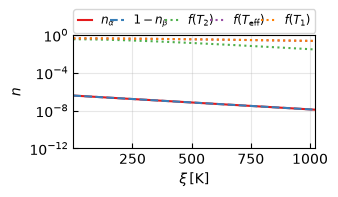

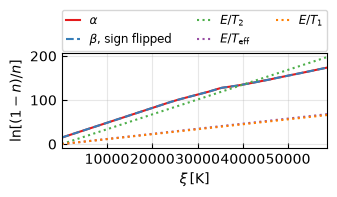

In [19]:
x = 0.5 * (xf[1:] + xf[:-1])                      # cell centres in xi
e, ns = np.hypot(x, s.d), len(x)
n, nb = cs.occ(s.mu)
k = np.abs(x) < 6 * d0                            # plotted part of the shell
ts = [(t2, r"T_2"), (teff, r"T_{\rm eff}"), (t1, r"T_1")]

fig, ax = plt.subplots(figsize=(W, 0.6 * W))
ax.semilogy(kel(x[k]), n[:ns][k], color=set1_list[0], label=r"$n_{\alpha}$")
ax.semilogy(kel(x[k]), nb[ns:][k], "--", color=set1_list[1], label=r"$1 - n_{\beta}$")
for i, (t, lb) in enumerate(ts):
    ax.semilogy(kel(x[k]), cm.fd(e[k], t), ":", color=set1_list[i + 2], label=rf"$f({lb})$")
ax.set_ylim(1e-12, 1)
ax.set_xlabel(r"$\xi\,[\mathrm{K}]$")
ax.set_ylabel(r"$n$")
ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand", borderaxespad=0, ncol=5,
          handlelength=1.2, columnspacing=0.6, fontsize="small")
style(ax, kel(x[k]))
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(W, 0.6 * W))
ax.plot(kel(x), s.mu[:ns], color=set1_list[0], label=r"$\alpha$")
ax.plot(kel(x), -s.mu[ns:], "--", color=set1_list[1], label=r"$\beta$, sign flipped")
for i, (t, lb) in enumerate(ts):
    ax.plot(kel(x), e / t, ":", color=set1_list[i + 2], label=rf"$E / {lb}$")
ax.set_xlabel(r"$\xi\,[\mathrm{K}]$")
ax.set_ylabel(r"$\ln[(1 - n) / n]$")
ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand", borderaxespad=0, ncol=3,
          handlelength=1.2, columnspacing=0.6, fontsize="small")
style(ax, kel(x))
plt.tight_layout()
plt.show()

T1 =  445.037 K: d = 174.0678 K, err 3.6e-13
T1 =  667.555 K: d = 174.0674 K, err 8.5e-14
T1 =  890.074 K: d = 173.9942 K, err 7.1e-14
T1 = 1112.592 K: d = 172.3092 K, err 4.3e-14
T1 = 1335.111 K: d = 158.6818 K, err 4.1e-11
T1 = 1557.629 K: d = 81.2991 K, err 6.0e-14
T1 = 1780.148 K: d = nan K, err 4.5e-11
T1 = 2002.666 K: d = nan K, err 3.4e-11
T1 = 2225.185 K: d = nan K, err 9.2e-11


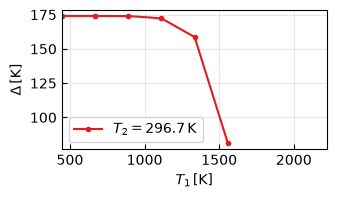

In [20]:
# Delta against T1 at T2 = 0.2 Tc (n = 201 cells)
t1r = np.linspace(0.3, 1.5, 9)
xf = cs.faces(c, 25 * tc * t1r.max(), 0.1 * d0, 201)     # e^-25 tails at the hottest T1
dn = []
for y in t1r:
    sy = cs.ness(c, xf, pc, qc, y * tc, t2)
    dn.append(sy.d if sy.t1 >= y * tc * (1 - 1e-12) else np.nan)
    print(f"T1 = {kel(y * tc):8.3f} K: d = {kel(dn[-1]):.4f} K, err {sy.err:.1e}")

fig, ax = plt.subplots(figsize=(W, 0.6 * W))
ax.plot(kel(t1r * tc), kel(dn), "o-", ms=3, color=set1_list[0], label=rf"$T_2 = {kel(t2):.1f}\,\mathrm{{K}}$")
ax.set_xlabel(r"$T_1\,[\mathrm{K}]$")
ax.set_ylabel(r"$\Delta\,[\mathrm{K}]$")
ax.legend()
style(ax, kel(t1r * tc))
plt.tight_layout()
plt.show()

## 5. BCS and BEC branch at the same $\Delta_0$

`cs.zero(..., branch="bec")` takes the largest-V root. Without a ring (`c.edge` = band edge $s = \pm 2$, here $\Gamma$)
the shell is anchored at the band edge: `cs.faces(c, ...)` gives offsets $0..\Lambda$ (at most the band), and
the cells stay fixed in $s$ while their $\xi$ moves with $m$. Everything downstream (`thermal_shell`, `ness`) is unchanged.

In [21]:
d0 = 0.015
cb = {br: cs.zero(**band, d0=d0, branch=br) for br in ("bcs", "bec")}
tcb = {br: cs.tc(c) for br, c in cb.items()}
for br, c in cb.items():
    p = c.p
    gx = 0.0 if c.edge is None else abs(cs.xc(p, c.m0) - (p.ta - p.tb) * c.edge)
    print(f"{br}: V = {kel(p.v):9.2f} K, 1 + m0 = {1 + c.m0:.3e}, edge {c.edge}, "
          f"min |xi| = {kel(gx):8.1f} K, Tc = {kel(tcb[br]):8.3f} K, Tc / d0 = {tcb[br] / d0:.3f}")

bcs: V =  14048.45 K, 1 + m0 = 5.413e-01, edge None, min |xi| =      0.0 K, Tc =   98.686 K, Tc / d0 = 0.567
bec: V =  96864.78 K, 1 + m0 = 8.646e-06, edge 2.0, min |xi| =  13618.4 K, Tc = 1483.456 K, Tc / d0 = 8.522


bcs: max |d_shell - d_quad| = 3.61e-02 K (n = 401)
bec: max |d_shell - d_quad| = 1.37e-03 K (n = 401)


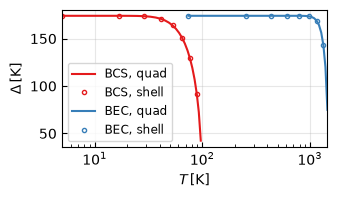

In [22]:
fig, ax = plt.subplots(figsize=(W, 0.6 * W))
tr = np.linspace(0.05, 0.98, 24)
for i, (br, c) in enumerate(cb.items()):
    tc = tcb[br]
    dq, z = [], (d0, c.m0)
    for t in tr * tc:
        z = cs.thermal(c, t, *z)[:2]
        dq.append(z)
    dq = np.array(dq)
    xf = cs.faces(c, 40 * tc, 0.1 * min(d0, 0.2 * tc), 401)
    ds = np.array([cs.thermal_shell(c, xf, t, *z)[0] for t, z in zip(tr[::3] * tc, dq[::3])])
    print(f"{br}: max |d_shell - d_quad| = {np.max(np.abs(kel(ds - dq[::3, 0]))):.2e} K (n = 401)")
    ax.semilogx(kel(tr * tc), kel(dq[:, 0]), color=set1_list[i], label=f"{br.upper()}, quad")
    ax.semilogx(kel(tr[::3] * tc), kel(ds), "o", ms=3, mfc="none", color=set1_list[i], label=f"{br.upper()}, shell")
ax.set_xlabel(r"$T\,[\mathrm{K}]$")
ax.set_ylabel(r"$\Delta\,[\mathrm{K}]$")
ax.legend(fontsize="small")
style(ax, kel(np.r_[tr * tcb["bcs"], tr * tcb["bec"]]))
plt.tight_layout()
plt.show()

T1 = T2: max residual of the shell equilibrium 2.8e-14
T1 = 1335.11 K, T2 = 296.69 K: d = 158.6800 K (d0 = 174.07 K), 1 + m = 7.5023e-06, err 1.7e-13, T_eff = 1259.34 K


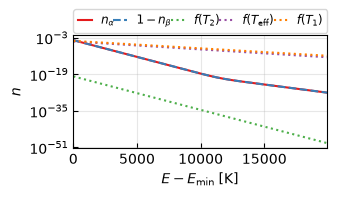

In [23]:
# BEC NESS, photon at T1 = 0.9 Tc, phonon (Fokker-Planck) at T2 = 0.2 Tc
c, tc = cb["bec"], tcb["bec"]
t1, t2 = 0.9 * tc, 0.2 * tc
pc = dict(amp=1.0, dip=2.0, c=200.0, w0=0.0, gam=0.1 * d0)
qc = dict(amp=1.0, ta_prime=-1.0, tb_prime=1.0, line="fp", gam=0.1 * d0)
xf = cs.faces(c, 40 * tc, 0.1 * min(d0, t2), 401)

d, m, mu = cs.thermal_shell(c, xf, t2, d0, c.m0)
r, _ = cs.resid(np.r_[mu, d, m], c, xf, pc, qc, t2, t2)
print(f"T1 = T2: max residual of the shell equilibrium {np.max(np.abs(r)):.1e}")
s = cs.ness(c, xf, pc, qc, t1, t2)
teff = brentq(lambda t: cs.thermal(c, t, s.d, s.m)[0] - s.d, 0.05 * tc, 0.99 * tc)
print(f"T1 = {kel(t1):.2f} K, T2 = {kel(t2):.2f} K: d = {kel(s.d):.4f} K (d0 = {kel(d0):.2f} K), "
      f"1 + m = {1 + s.m:.4e}, err {s.err:.1e}, T_eff = {kel(teff):.2f} K")

gr = cs.cells(c, xf, s.m)
x = 0.5 * (gr.xf[1:] + gr.xf[:-1])
e, ns = np.hypot(x, s.d), len(x)
n, nb = cs.occ(s.mu)
k = e - e.min() < 15 * t1                         # plotted part of the shell
de = kel(e[k] - e.min())
fig, ax = plt.subplots(figsize=(W, 0.6 * W))
ax.semilogy(de, n[:ns][k], color=set1_list[0], label=r"$n_{\alpha}$")
ax.semilogy(de, nb[ns:][k], "--", color=set1_list[1], label=r"$1 - n_{\beta}$")
for i, (t, lb) in enumerate([(t2, r"T_2"), (teff, r"T_{\rm eff}"), (t1, r"T_1")]):
    ax.semilogy(de, cm.fd(e[k], t), ":", color=set1_list[i + 2], label=rf"$f({lb})$")
ax.set_xlabel(r"$E - E_{\min}\,[\mathrm{K}]$")
ax.set_ylabel(r"$n$")
ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand", borderaxespad=0, ncol=5,
          handlelength=1.2, columnspacing=0.6, fontsize="small")
style(ax, de)
plt.tight_layout()
plt.show()